In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [83]:
features = [
    "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
    "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT", "MEDV"
]

data = pd.read_csv(
    "./assn2 material/housing.data",
    sep=r"\s+",
    header=None,
    names=features
)

X = data.drop(columns="MEDV").to_numpy()
y = data["MEDV"].to_numpy()

In [84]:
def polynomial_features(X, degree):
    features = [np.ones(X.shape[0])]

    for power in range(1, degree + 1):
        features.append(X ** power)

    return np.column_stack(features)

def polynomial_regression(X_train, y_train, X_test, y_test, degree):
    Phi_train = polynomial_features(X_train, degree)
    Phi_test = polynomial_features(X_test, degree)

    weights = np.linalg.lstsq(Phi_train, y_train, rcond=None)[0]

    train_pred = Phi_train @ weights
    test_pred = Phi_test @ weights

    train_rms = np.sqrt(np.mean((y_train - train_pred) ** 2))
    test_rms = np.sqrt(np.mean((y_test - test_pred) ** 2))

    return train_rms, test_rms, weights

def normalize(X_train_raw, X_test_raw):
    mean = X_train_raw.mean(axis=0)
    std = X_train_raw.std(axis=0)
    std[std == 0] = 1

    X_train = (X_train_raw - mean) / std
    X_test = (X_test_raw - mean) / std

    return X_train, X_test

In [85]:
X_train_raw, X_test_raw = X[:100], X[100:]
y_train, y_test = y[:100], y[100:]

X_train, X_test = normalize(X_train_raw, X_test_raw)

degrees = range(1, 8)
train_errors = []
test_errors = []

for degree in degrees:
    train_rms, test_rms, weights = polynomial_regression(
        X_train, y_train, X_test, y_test, degree
    )

    train_errors.append(train_rms)
    test_errors.append(test_rms)

    print(
        f"Degree {degree}: "
        f"Training RMS = {train_rms:.4f}, "
        f"Testing RMS = {test_rms:.4f}"
    )


Degree 1: Training RMS = 2.0372, Testing RMS = 36.4449
Degree 2: Training RMS = 1.5781, Testing RMS = 1097.1883
Degree 3: Training RMS = 1.4491, Testing RMS = 48672.8178
Degree 4: Training RMS = 1.2705, Testing RMS = 21859310.1962
Degree 5: Training RMS = 1.0966, Testing RMS = 18358040619.6942
Degree 6: Training RMS = 1.0725, Testing RMS = 5024088562298.6279
Degree 7: Training RMS = 0.8815, Testing RMS = 6879332106083146.0000


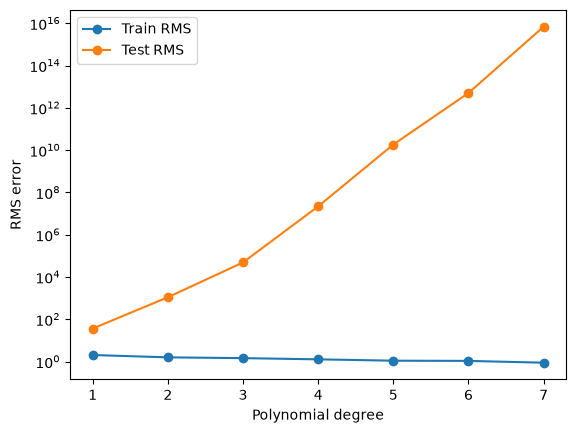

In [86]:
plt.plot(degrees, train_errors, marker='o', label='Train RMS')
plt.plot(degrees, test_errors, marker='o', label='Test RMS')
plt.xlabel('Polynomial degree')
plt.ylabel('RMS error')
plt.yscale('log')
plt.legend()

plt.savefig("media/polynomial_regression_errors.png", dpi=300, bbox_inches='tight')
plt.show()

We can see that the training error decreases as the degree of the polynomial increases, which is expected since higher-degree polynomials can fit the training data better. This also leads to overfitting, as shown by the increasing testing error for higher-degree polynomials. The best test performance is at degree 1.

In [87]:
Phi_train = polynomial_features(X_train, degree=1)
weights = np.linalg.lstsq(Phi_train, y_train, rcond=None)[0]

print("Bias:", round(weights[0], 4))
print("RM weight:", round(weights[6], 4))
print("DIS weight:", round(weights[8], 4))
print("All weights:", np.round(weights, 4))

Bias: 22.309
RM weight: 4.1956
DIS weight: 0.0107
All weights: [ 2.2309e+01 -1.3380e+00  1.2300e-01 -5.3110e-01  0.0000e+00  1.0027e+00
  4.1956e+00 -2.1663e+00  1.0700e-02 -1.9380e-01 -3.4860e-01  2.6130e-01
  1.8110e-01  1.4880e-01]


The RM weight (4.196) seems reasonable because houses with more rooms generally have higher values. The DIS weight (0.0107) is very small, suggesting that distance has little effect on the prediction when other features are held constant.

Degree 1: Training RMS = 5.2393, Testing RMS = 9.8555
Degree 2: Training RMS = 4.3528, Testing RMS = 18.5269
Degree 3: Training RMS = 4.3524, Testing RMS = 17.2528
Degree 4: Training RMS = 4.2537, Testing RMS = 84.1407
Degree 5: Training RMS = 4.2266, Testing RMS = 176.8406
Degree 6: Training RMS = 4.2139, Testing RMS = 1009.1254
Degree 7: Training RMS = 3.9944, Testing RMS = 29250.4971


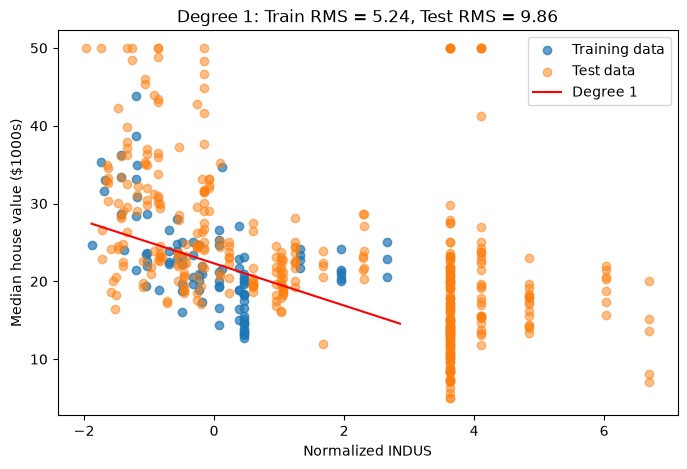

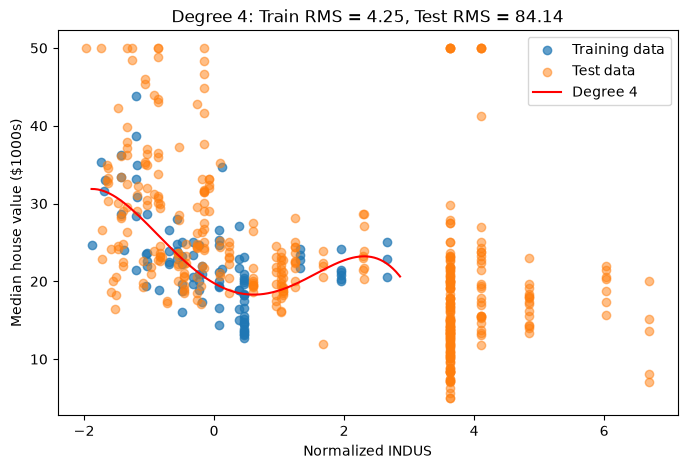

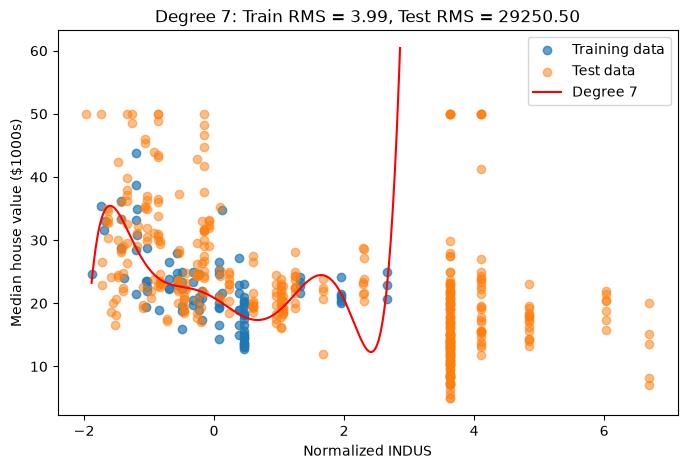

In [88]:
X_train_raw, X_test_raw = X[:100], X[100:]
y_train, y_test = y[:100], y[100:]

X_train, X_test = normalize(X_train_raw, X_test_raw)

# Feature 3: INDUS - X_n(: ,2)
x_train = X_train[:, 2]
x_test = X_test[:, 2]

# Evaluate all degrees
for degree in range(1, 8):
    train_rms, test_rms, weights = polynomial_regression(
        x_train, y_train, x_test, y_test, degree
    )

    print(
        f"Degree {degree}: "
        f"Training RMS = {train_rms:.4f}, "
        f"Testing RMS = {test_rms:.4f}"
    )

# Plot selected degrees
for degree in [1, 4, 7]:
    train_rms, test_rms, weights = polynomial_regression(
        x_train, y_train, x_test, y_test, degree
    )

    # Generate the plotting grid using the training range
    grid = np.linspace(x_train.min(), x_train.max()+0.2, 300)
    predictions = polynomial_features(grid, degree) @ weights

    plt.figure(figsize=(8, 5))
    plt.scatter(x_train, y_train, label="Training data", alpha=0.7)
    plt.scatter(x_test, y_test, label="Test data", alpha=0.5)
    plt.plot(grid, predictions, "r-", label=f"Degree {degree}")

    plt.xlabel("Normalized INDUS")
    plt.ylabel("Median house value ($1000s)")
    plt.title(
        f"Degree {degree}: Train RMS = {train_rms:.2f}, "
        f"Test RMS = {test_rms:.2f}"
    )
    plt.legend()

    plt.savefig(f"media/indus_degree_{degree}.png", bbox_inches="tight")
    plt.show()
    plt.close()

We tested polynomial degrees 1 through 7 to compare models of different complexity. As shown in the table, training RMS generally decreased as the degree increased, while testing RMS increased significantly for higher degrees. This suggests overfitting, where more complex models fit the training data better but perform poorly on unseen data. From the table, we can see that degree 1 have the lowest testing RMS.

In [89]:
def polynomial_regression_reg(x_train, y_train, degree, lam):
    Phi = polynomial_features(x_train, degree)
    P = np.sqrt(lam) * np.eye(degree + 1)
    P[0, 0] = 0
    Phi_aug = np.vstack([Phi, P])
    y_aug = np.concatenate([y_train, np.zeros(degree + 1)])
    return np.linalg.lstsq(Phi_aug, y_aug, rcond=None)[0]

def cross_validate(x, y, feature_idx, degree, lambdas, k=10, seed=0):
    idx = np.random.default_rng(seed).permutation(len(x))
    folds = np.array_split(idx, k)
    avg_errors = []

    for lam in lambdas:
        fold_errors = []
        
        for i in range(k):
            val = folds[i]
            tr = np.concatenate([folds[j] for j in range(k) if j != i])

            x_train, x_valid = normalize(x[tr], x[val])
            x_train = x_train[:, feature_idx]
            x_valid = x_valid[:, feature_idx]

            w = polynomial_regression_reg(x_train, y[tr], degree, lam)
            pred = polynomial_features(x_valid, degree) @ w
            fold_errors.append(np.sqrt(np.mean((y[val] - pred) ** 2)))

        avg_errors.append(np.mean(fold_errors))

    return np.array(avg_errors)

In [90]:
X_train_raw = X[:100]
y_train = y[:100]

feature_idx = 1
degree = 8
lambdas = [0, 0.01, 0.1, 1, 10, 100, 1000]

avg_val_errors = cross_validate(
    X_train_raw,
    y_train,
    feature_idx=feature_idx,
    degree=degree,
    lambdas=lambdas
)

for lam, error in zip(lambdas, avg_val_errors):
    print(f"lambda = {lam}: average validation RMS = {error:.4f}")

best_idx = np.argmin(avg_val_errors)
best_lam = lambdas[best_idx]

print(f"Best lambda: {best_lam}")

lambda = 0: average validation RMS = 178.3534
lambda = 0.01: average validation RMS = 10.1131
lambda = 0.1: average validation RMS = 9.9645
lambda = 1: average validation RMS = 8.1006
lambda = 10: average validation RMS = 8.4320
lambda = 100: average validation RMS = 8.5710
lambda = 1000: average validation RMS = 7.5711
Best lambda: 1000


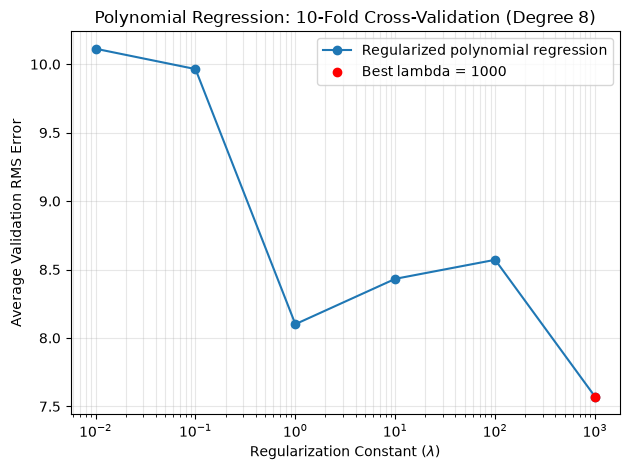

In [91]:
plt.figure()

plt.semilogx(
    lambdas[1:],
    avg_val_errors[1:],
    marker='o',
    label='Regularized'
)

if best_lam > 0:
    plt.scatter(
        best_lam,
        avg_val_errors[best_idx],
        color='red',
        zorder=3,
        label=f'Best lambda = {best_lam}'
    )

plt.xlabel('Regularization Constant ($\\lambda$)')
plt.ylabel('Average Validation RMS Error')
plt.title('Polynomial Regression: 10-Fold Cross-Validation (Degree 8)')
plt.grid(True, which='both', alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("media/polynomial_regularization_cv.png", dpi=300, bbox_inches="tight")
plt.show()

Without regularization the degree 8 polynomial overfits badly, with an average validation RMS of 178.35. Adding the penalty reduces the error sharply, reaching its lowest value of 7.57 at $\lambda$ = 1000. I would choose $\lambda$ = 1000.

In [92]:
def gaussian_features(X, centers, s):
    d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    phi = np.exp(-d2 / (2 * s ** 2))
    return np.column_stack([np.ones(X.shape[0]), phi])

def gaussian_regression(X_train, y_train, X_test, y_test, Ks, s, seed=0):
    perm = np.random.default_rng(seed).permutation(len(X_train))
    train_errors, test_errors = [], []

    for K in Ks:
        centers = X_train[perm[:K]]
        Phi_train = gaussian_features(X_train, centers, s)
        Phi_test = gaussian_features(X_test, centers, s)

        w = np.linalg.lstsq(Phi_train, y_train, rcond=None)[0]

        train_pred = Phi_train @ w
        test_pred = Phi_test @ w

        train_rms = np.sqrt(np.mean((train_pred - y_train) ** 2))
        test_rms = np.sqrt(np.mean((test_pred - y_test) ** 2))

        train_errors.append(train_rms)
        test_errors.append(test_rms)

    return train_errors, test_errors

Gaussian regression results:
K = 5: Training RMS = 3.5712, Testing RMS = 10.6803
K = 15: Training RMS = 2.1720, Testing RMS = 8.7528
K = 25: Training RMS = 1.5906, Testing RMS = 9.4498
K = 35: Training RMS = 1.4642, Testing RMS = 9.6442
K = 45: Training RMS = 1.2121, Testing RMS = 8.4540
K = 55: Training RMS = 1.1100, Testing RMS = 10.4087
K = 65: Training RMS = 1.0330, Testing RMS = 9.1681
K = 75: Training RMS = 0.9481, Testing RMS = 8.8415
K = 85: Training RMS = 0.8646, Testing RMS = 10.5398
K = 95: Training RMS = 0.2858, Testing RMS = 54.4899


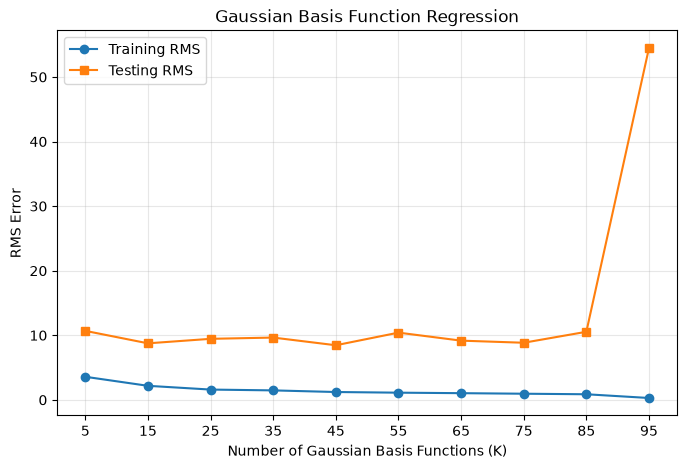

In [93]:
X_train_raw, X_test_raw = X[:100], X[100:]
y_train, y_test = y[:100], y[100:]

X_train, X_test = normalize(X_train_raw, X_test_raw)

# Number of Gaussian basis functions
Ks = list(range(5, 100, 10))

diffs = X_train[:, None, :] - X_train[None, :, :]
dists = np.sqrt((diffs ** 2).sum(axis=2))
s = np.median(dists[np.triu_indices_from(dists, k=1)])

g_train, g_test = gaussian_regression(
    X_train, y_train,
    X_test, y_test,
    Ks, s
)

# Print results
print("Gaussian regression results:")
for K, train_rms, test_rms in zip(Ks, g_train, g_test):
    print(
        f"K = {K}: "
        f"Training RMS = {train_rms:.4f}, "
        f"Testing RMS = {test_rms:.4f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(Ks, g_train, 'o-', label='Training RMS')
plt.plot(Ks, g_test, 's-', label='Testing RMS')

plt.xlabel('Number of Gaussian Basis Functions (K)')
plt.ylabel('RMS Error')
plt.title('Gaussian Basis Function Regression')
plt.xticks(Ks)
plt.grid(True, alpha=0.3)
plt.legend()

plt.savefig(
    "media/gaussian_regression.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

As the number of basis functions increases, the training error generally decreases, while the test RMS error fluatuates without a clear trend. At K = 95, the test error increases sharply while the training error continues to decrease, indicating overfitting. The best test performance is at K = 45.

In [94]:
def gaussian_regression_reg(X_train, y_train, centers, sigma, lam):
    Phi = gaussian_features(X_train, centers, sigma)
    P = np.sqrt(lam) * np.eye(Phi.shape[1])
    P[0, 0] = 0
    Phi_aug = np.vstack([Phi, P])
    y_aug = np.concatenate([y_train, np.zeros(Phi.shape[1])])
    return np.linalg.lstsq(Phi_aug, y_aug, rcond=None)[0]

def median_bandwidth(X):
    dists = np.sqrt(
        ((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2)
    )
    return np.median(dists[np.triu_indices(len(X), k=1)])

def cross_validate_gaussian(X, y, lambdas, k=10, seed=0):
    idx = np.random.default_rng(seed).permutation(len(X))
    folds = np.array_split(idx, k)
    avg_errors = []

    for lam in lambdas:
        fold_errors = []

        for i in range(k):
            val = folds[i]
            tr = np.concatenate([folds[j] for j in range(k) if j != i])

            X_train, X_valid = normalize(X[tr], X[val])
            centers = X_train
            sigma = median_bandwidth(X_train)

            w = gaussian_regression_reg(X_train, y[tr], centers, sigma, lam)
            pred = gaussian_features(X_valid, centers, sigma) @ w
            fold_errors.append(np.sqrt(np.mean((y[val] - pred) ** 2)))

        avg_errors.append(np.mean(fold_errors))

    return np.array(avg_errors)


In [95]:
X_train_raw = X[:100]
y_train = y[:100]

lambdas = [0, 0.01, 0.1, 1, 10, 100, 1000]

avg_val_errors = cross_validate_gaussian(
    X_train_raw, y_train, lambdas
)

for lam, error in zip(lambdas, avg_val_errors):
    print(f"lambda = {lam}: average validation RMS = {error:.4f}")

best_idx = np.argmin(avg_val_errors)
best_lam = lambdas[best_idx]

print("Best lambda:", best_lam)

lambda = 0: average validation RMS = 8.0366
lambda = 0.01: average validation RMS = 2.0516
lambda = 0.1: average validation RMS = 2.2467
lambda = 1: average validation RMS = 2.6324
lambda = 10: average validation RMS = 3.2206
lambda = 100: average validation RMS = 4.2976
lambda = 1000: average validation RMS = 5.3454
Best lambda: 0.01


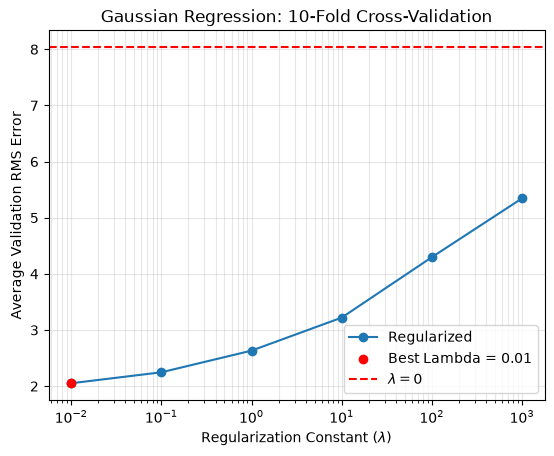

In [99]:
plt.figure()

plt.semilogx(
    lambdas[1:],
    avg_val_errors[1:],
    marker='o',
    label='Regularized'
)

if best_lam > 0:
    plt.scatter(
        best_lam,
        avg_val_errors[best_idx],
        color='red',
        zorder=3,
        label=f'Best Lambda = {best_lam}'
    )

plt.axhline(
    avg_val_errors[0],
    color='r',
    linestyle='--',
    label=r'$\lambda = 0$'
)

plt.xlabel('Regularization Constant ($\\lambda$)')
plt.ylabel('Average Validation RMS Error')
plt.title('Gaussian Regression: 10-Fold Cross-Validation')
plt.grid(True, which='both', alpha=0.3)
plt.legend()

plt.savefig("media/gaussian_regularization_cv.png", dpi=300, bbox_inches="tight")
plt.show()

I would choose $\lambda$ = 0.01 because it has the lowest validation error (2.03). 